# DTAAD v3: closer to the authors' released code

### Paper: Yu, Lu & Xue, *DTAAD*, Knowledge-Based Systems 295 (2024).
### Datasets: NASA **SMAP** and **MSL**

In [1]:
import os, ast, math, time, copy
os.environ['TMP'] = os.environ['TEMP'] = r'D:\Personal\5th sem\ml_course\tmp_dtaad'   # temp files on D:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import weight_norm
from scipy.stats import genpareto
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

DATA = 'data/SMAP_MSL' if os.path.isdir('data/SMAP_MSL') else '../data/SMAP_MSL'
os.makedirs('results', exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Hyper-parameters (paper, Appendix A) and the authors' threshold settings (src/constants.py, src/pot.py)
WINDOW = 10            # sliding window length
LAMBDA = 0.8           # loss weight of the global (fed-back) decoder
HIDDEN = 16            # hidden units of the feed-forward layers
DROPOUT = 0.2
BATCH = 128
MAX_EPOCHS = 20        # short training; the authors' script trains for only 5 epochs
PATIENCE = 5
LR = {'SMAP': 1e-3, 'MSL': 2e-3}
POT_LEVEL = {'SMAP': 0.98, 'MSL': 0.999}   # initial threshold = this quantile of the training scores
POT_SCALE = {'SMAP': 1.00, 'MSL': 1.04}    # final multiplier on the threshold
POT_Q = 1e-5
CHANNEL = {'SMAP': 'P-1', 'MSL': 'C-1'}
SEEDS = [0, 1, 2, 3, 4]
print('device:', device, '| data:', DATA)

device: cuda | data: ../data/SMAP_MSL


## 1. Data

SMAP P-1: 25 dims, train 2872, test 8505, anomalies 8.8%, columns constant in train: 9
MSL C-1: 55 dims, train 2158, test 2264, anomalies 13.8%, columns constant in train: 40


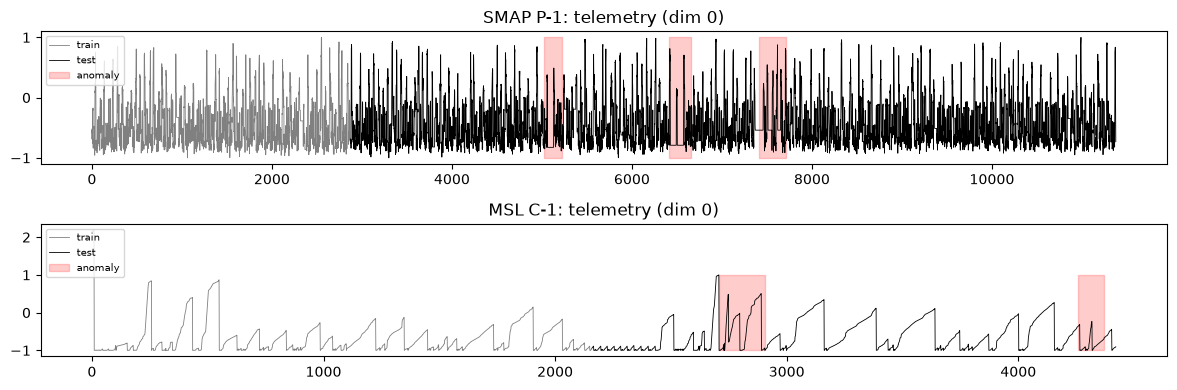

In [2]:
meta = pd.read_csv(f'{DATA}/labeled_anomalies.csv').drop_duplicates('chan_id')   # P-2 is listed twice

def load_channel(chan):
    train = np.load(f'{DATA}/train/{chan}.npy')
    test = np.load(f'{DATA}/test/{chan}.npy')
    labels = np.zeros(len(test), dtype=int)
    for start, end in ast.literal_eval(meta[meta.chan_id == chan].anomaly_sequences.iloc[0]):
        labels[start:end + 1] = 1
    return train, test, labels

for ds, chan in CHANNEL.items():
    train, test, labels = load_channel(chan)
    print(f'{ds} {chan}: {train.shape[1]} dims, train {len(train)}, test {len(test)}, '
          f'anomalies {labels.mean():.1%}, columns constant in train: {(train.std(0) == 0).sum()}')

fig, axes = plt.subplots(2, 1, figsize=(12, 4))
for ax, (ds, chan) in zip(axes, CHANNEL.items()):
    train, test, labels = load_channel(chan)
    ax.plot(np.arange(len(train)), train[:, 0], lw=0.6, color='gray', label='train')
    ax.plot(np.arange(len(train), len(train) + len(test)), test[:, 0], lw=0.6, color='black', label='test')
    ax.fill_between(np.arange(len(train), len(train) + len(test)), -1, 1, where=labels == 1,
                    color='red', alpha=0.2, label='anomaly')
    ax.set_title(f'{ds} {chan}: telemetry (dim 0)'); ax.legend(loc='upper left', fontsize=7)
plt.tight_layout(); plt.savefig('results/1_data.png', dpi=150); plt.show()

## 2. Preprocessing (same as v2, Section 3.2 of the paper)
1. **Min-max scaling** with the training min/max (Eq. 3). A column that never changes in training is divided by
   1e-4, so any change in it at test time becomes a very large value. This turns out to be the main anomaly signal
   on these channels: a command that never occurred in training (Section 9 shows that removing it breaks detection).
2. **White-noise augmentation** at SNR = 50 dB, added as ε/100 (Eq. 4–5). Training data only.
3. **Sliding windows** of length 10 ending at the current step, padded at the start by repeating x₁.

P-1 normalised train range [-0.000, 1.000], test max 10000


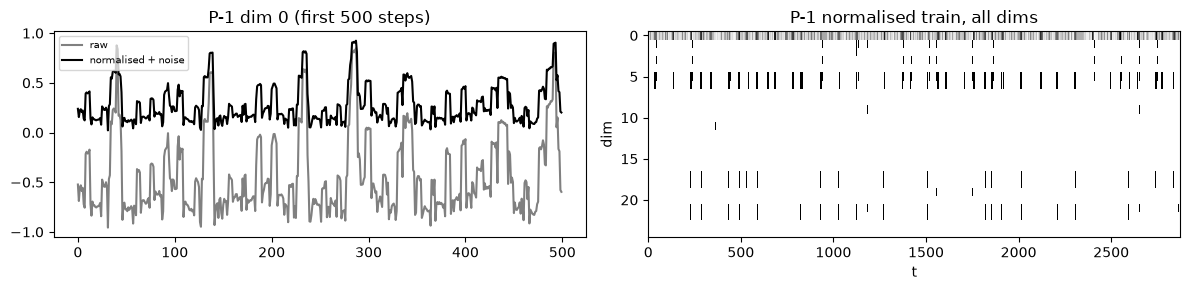

In [3]:
def preprocess(train, test, seed=0):
    lo, hi = train.min(0), train.max(0)
    train = (train - lo) / (hi - lo + 1e-4)                              # Eq. 3
    test = (test - lo) / (hi - lo + 1e-4)
    noise_power = np.mean(train ** 2, axis=0) / 10 ** (50 / 10)          # Eq. 4 (SNR = 50 dB)
    noise = np.random.default_rng(seed).normal(size=train.shape) * np.sqrt(noise_power)
    return train + noise / 100, test                                     # Eq. 5

def make_windows(x):
    padded = np.concatenate([np.repeat(x[:1], WINDOW - 1, axis=0), x])
    windows = np.stack([padded[t:t + WINDOW] for t in range(len(x))])   # (time, window, dims)
    return torch.tensor(windows, dtype=torch.float32, device=device)

train_raw, test_raw, _ = load_channel('P-1')
train_n, test_n = preprocess(train_raw, test_raw)
print(f'P-1 normalised train range [{train_n.min():.3f}, {train_n.max():.3f}], test max {test_n.max():.0f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(train_raw[:500, 0], color='gray', label='raw'); axes[0].plot(train_n[:500, 0], color='black', label='normalised + noise')
axes[0].set_title('P-1 dim 0 (first 500 steps)'); axes[0].legend(fontsize=7)
axes[1].imshow(train_n.T, aspect='auto', interpolation='nearest', cmap='gray_r')
axes[1].set(title='P-1 normalised train, all dims', xlabel='t', ylabel='dim')
plt.tight_layout(); plt.savefig('results/2_preprocessing.png', dpi=150); plt.show()

## 3. Model
* **Local branch:** causal TCN (3 layers, kernel 4) → Transformer encoder → decoder, giving prediction O₂.
* **Feedback:** O₂ is added to every step of the window.
* **Global branch:** dilated TCN (dilations 1, 2, 4, kernel 3) → encoder → decoder, giving the final prediction Ô₁.
* Encoder: positional encoding, multi-head attention with heads = number of dims, FFN, post-LayerNorm.

In [4]:
class TCNLayer(nn.Module):
    def __init__(self, channels, kernel, dilation):
        super().__init__()
        self.pad = (kernel - 1) * dilation
        self.conv = weight_norm(nn.Conv1d(channels, channels, kernel, dilation=dilation))
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):                                   # x: (batch, dims, time)
        return self.drop(F.leaky_relu(self.conv(F.pad(x, (self.pad, 0))), 0.01))

def make_tcn(dims, kind):
    if kind == 'local':
        return nn.Sequential(*[TCNLayer(dims, 4, 1) for _ in range(3)])
    n_layers = math.ceil(math.log2((WINDOW - 1) / (3 - 1) + 1))          # Eq. 20 -> 3 layers
    return nn.Sequential(*[TCNLayer(dims, 3, 2 ** i) for i in range(n_layers)])

def ffn(d_in, d_out):                                                    # Eq. 24
    return nn.Sequential(nn.Linear(d_in, HIDDEN), nn.LeakyReLU(0.01), nn.Linear(HIDDEN, d_out))

def positional_encoding(length, dims):
    pos = torch.arange(length).unsqueeze(1)
    freq = torch.exp(torch.arange(0, dims, 2) * (-math.log(10000.0) / dims))
    pe = torch.zeros(length, dims)
    pe[:, 0::2] = torch.sin(pos * freq)
    pe[:, 1::2] = torch.cos(pos * freq)[:, :dims // 2]
    return pe

class Branch(nn.Module):
    """TCN -> Transformer encoder -> decoder. Input (batch, window, dims), output (batch, dims)."""
    def __init__(self, dims, kind, use_transformer=True):
        super().__init__()
        self.tcn = make_tcn(dims, kind)
        self.use_transformer = use_transformer
        self.register_buffer('pe', positional_encoding(WINDOW, dims))
        self.attention = nn.MultiheadAttention(dims, num_heads=dims, dropout=DROPOUT, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(dims), nn.LayerNorm(dims)
        self.encoder_ffn, self.residual_ffn = ffn(dims, dims), ffn(dims, dims)
        self.decoder = ffn(WINDOW, 1)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        h = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        if self.use_transformer:                                         # Eq. 25
            h = h * math.sqrt(h.shape[-1]) + self.pe
            h = self.norm1(h + self.drop(self.attention(h, h, h)[0]))
            h = self.norm2(h + self.drop(self.encoder_ffn(h)))
        h = h + self.residual_ffn(h)                                     # Eq. 26
        return torch.sigmoid(self.decoder(h.transpose(1, 2))).squeeze(-1)

class DTAAD(nn.Module):
    """The flags switch components off for the ablation study (Table 7)."""
    def __init__(self, dims, local=True, glob=True, feedback=True, transformer=True):
        super().__init__()
        self.local = Branch(dims, 'local', transformer) if local else None
        self.glob = Branch(dims, 'global', transformer) if glob else None
        self.feedback = feedback

    def forward(self, x):
        o2 = self.local(x) if self.local else None                       # local prediction
        if self.glob is None:
            return None, o2
        if self.feedback and o2 is not None:
            x = x + o2.unsqueeze(1)                                      # feed O2 back over the whole window
        return self.glob(x), o2                                          # global prediction Ô1

print('parameters (25 dims):', sum(p.numel() for p in DTAAD(25).parameters()))

parameters (25 dims): 22575


## 4. Training (short)
* Loss (Eq. 28): 0.8·MSE(Ô₁, xₜ) + 0.2·MSE(O₂, xₜ). AdamW (weight decay 1e-5), learning rate ×0.9 every 5 epochs.
* At most **20 epochs** with early stopping on a validation split (the last 20% of the training series).
  v2 trained for up to 100 epochs; the design study showed that shorter training is both faster and better
  (the authors' own script uses just 5 epochs).
* No MAML: removing it changed nothing in the design study and halves the training time. The authors' code does not implement it either.

In [5]:
def loss_fn(model, x):
    o1, o2 = model(x)
    target = x[:, -1]                                                    # the current step x_t
    if o1 is None: return F.mse_loss(o2, target)
    if o2 is None: return F.mse_loss(o1, target)
    return LAMBDA * F.mse_loss(o1, target) + (1 - LAMBDA) * F.mse_loss(o2, target)

def train_model(model, train_w, val_w, lr):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.9)
    history, best, best_state, bad_epochs = [], float('inf'), None, 0
    for epoch in range(MAX_EPOCHS):
        start = time.time()
        model.train()
        losses = []
        for idx in torch.randperm(len(train_w)).split(BATCH):
            loss = loss_fn(model, train_w[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        sched.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model, val_w).item()
        history.append({'epoch': epoch + 1, 'train': np.mean(losses), 'val': val, 'seconds': time.time() - start})
        if val < best:
            best, best_state, bad_epochs = val, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                break
    model.load_state_dict(best_state)
    return pd.DataFrame(history)

## 5. Score, threshold and metrics (as in the authors' `main.py` and `src/pot.py`)
* **Score:** squared error between xₜ and Ô₁, **averaged over all dimensions** (one number per time step):
  `lossFinal = np.mean(loss, axis=1)`.
* **Threshold:** POT on the mean training scores.

In [6]:
@torch.no_grad()
def anomaly_scores(model, windows):
    model.eval()
    o1, o2 = model(windows)
    pred = o1 if o1 is not None else o2
    return ((pred - windows[:, -1]) ** 2).cpu().numpy()

def authors_pot_threshold(train_score, test_score, ds):
    level = POT_LEVEL[ds]
    while True:                                          # the authors lower the level until the fit works
        t = np.sort(train_score)[int(level * len(train_score))]
        peaks = train_score[train_score > t] - t
        if len(peaks) >= 2 or level < 0.5:
            break
        level *= 0.999
    if len(peaks) < 2 or peaks.std() == 0:               # degenerate case: (almost) constant scores
        return train_score.max() * POT_SCALE[ds]
    gamma, _, beta = genpareto.fit(peaks, floc=0)        # maximum likelihood
    r = POT_Q * len(train_score) / len(peaks)
    z = t - beta * np.log(r) if abs(gamma) < 1e-8 else t + beta / gamma * (r ** (-gamma) - 1)
    above = np.where(test_score > t)[0]
    first = above[0] if len(above) else len(test_score)  # from here on SPOT uses t instead of z
    thresholds = np.r_[np.full(first, z), np.full(len(test_score) - first, t)]
    return thresholds.mean() * POT_SCALE[ds]

def point_adjust(pred, labels):
    pred = pred.copy()
    edges = np.diff(np.r_[0, labels, 0])
    for start, end in zip(np.where(edges == 1)[0], np.where(edges == -1)[0]):
        if pred[start:end].any():
            pred[start:end] = True
    return pred

def f1_score(pred, labels):
    tp = (pred & (labels == 1)).sum()
    precision, recall = tp / max(pred.sum(), 1), tp / labels.sum()
    return precision, recall, 2 * precision * recall / max(precision + recall, 1e-12)

def evaluate(train_scores, test_scores, labels, ds):
    train_score, test_score = train_scores.mean(axis=1), test_scores.mean(axis=1)   # mean over dimensions
    threshold = authors_pot_threshold(train_score, test_score, ds)
    pred = test_score >= threshold
    adjusted = point_adjust(pred, labels)
    p, r, f1 = f1_score(adjusted, labels)
    return {'P': p, 'R': r, 'F1': f1, 'AUC': roc_auc_score(labels, adjusted),
            'raw F1': f1_score(pred, labels)[2]}, threshold

## 6. Running an experiment

In [7]:
def run(ds, train_fraction=1.0, seed=0, **variant):
    torch.manual_seed(seed); np.random.seed(seed)
    train, test, labels = load_channel(CHANNEL[ds])
    if train_fraction < 1:                                    # "20% data" setting: middle slice of the series
        mid, half = len(train) // 2, int(len(train) * train_fraction / 2)
        train = train[mid - half: mid + half]
    train, test = preprocess(train, test, seed)
    train_w, test_w = make_windows(train), make_windows(test)
    n_val = len(train_w) // 5
    model = DTAAD(train.shape[1], **variant).to(device)
    history = train_model(model, train_w[:-n_val], train_w[-n_val:], LR[ds])
    train_scores, test_scores = anomaly_scores(model, train_w), anomaly_scores(model, test_w)
    metrics, threshold = evaluate(train_scores, test_scores, labels, ds)
    metrics['epochs'], metrics['s/epoch'] = len(history), history.seconds.mean()
    return dict(metrics=metrics, history=history, test_score=test_scores.mean(axis=1),
                threshold=threshold, labels=labels)

## 7. Main results (100% and 20% training data, 5 seeds; compare with Tables 3 and 4)

In [8]:
runs = {(ds, frac): [run(ds, frac, seed) for seed in SEEDS] for ds in CHANNEL for frac in (1.0, 0.2)}
paper = {('SMAP', 1.0): (0.902, 0.991), ('SMAP', 0.2): (0.900, 0.989),
         ('MSL', 1.0): (0.950, 0.992), ('MSL', 0.2): (0.921, 0.986)}
rows = []
for (ds, frac), rs in runs.items():
    m = pd.DataFrame([r['metrics'] for r in rs])
    rows.append({'dataset': f'{ds} {CHANNEL[ds]}', 'train data': f'{frac:.0%}',
                 'P': f"{m.P.mean():.3f}", 'R': f"{m.R.mean():.3f}",
                 'F1 (ours)': f"{m.F1.mean():.3f} ± {m.F1.std():.3f}", 'F1 (paper)': paper[ds, frac][0],
                 'AUC (ours)': f"{m.AUC.mean():.3f}", 'AUC (paper)': paper[ds, frac][1],
                 'raw F1': f"{m['raw F1'].mean():.3f}", 's/epoch': f"{m['s/epoch'].mean():.2f}"})
table = pd.DataFrame(rows)
print(table.to_string(index=False))

 dataset train data     P     R     F1 (ours)  F1 (paper) AUC (ours)  AUC (paper) raw F1 s/epoch
SMAP P-1       100% 0.811 1.000 0.895 ± 0.004       0.902      0.989        0.991  0.045    0.56
SMAP P-1        20% 0.795 1.000 0.886 ± 0.011       0.900      0.987        0.989  0.041    0.13
 MSL C-1       100% 0.881 1.000 0.936 ± 0.025       0.950      0.989        0.992  0.073    0.45
 MSL C-1        20% 0.730 1.000 0.844 ± 0.020       0.921      0.970        0.986  0.236    0.10


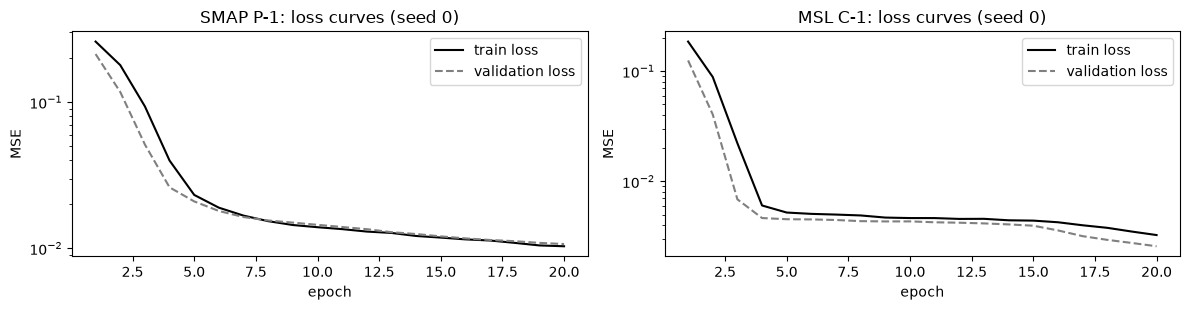

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, ds in zip(axes, CHANNEL):
    h = runs[ds, 1.0][0]['history']
    ax.plot(h.epoch, h.train, color='black', label='train loss')
    ax.plot(h.epoch, h.val, color='gray', ls='--', label='validation loss')
    ax.set(yscale='log', xlabel='epoch', ylabel='MSE', title=f'{ds} {CHANNEL[ds]}: loss curves (seed 0)'); ax.legend()
plt.tight_layout(); plt.savefig('results/3_loss_curves.png', dpi=150); plt.show()

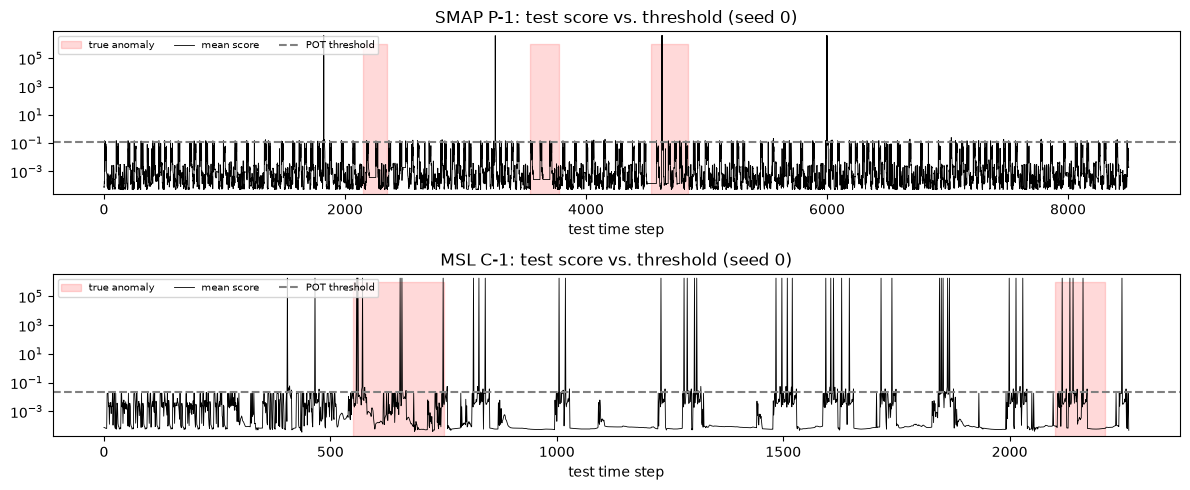

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5))
for ax, ds in zip(axes, CHANNEL):
    r = runs[ds, 1.0][0]
    t = np.arange(len(r['labels']))
    ax.fill_between(t, 1e-6, 1e6, where=r['labels'] == 1, color='red', alpha=0.15, label='true anomaly')
    ax.plot(t, r['test_score'], lw=0.6, color='black', label='mean score')
    ax.axhline(r['threshold'], color='gray', ls='--', label='POT threshold')
    ax.set(yscale='log', ylim=(r['test_score'].min() * 0.5, r['test_score'].max() * 2),
           title=f'{ds} {CHANNEL[ds]}: test score vs. threshold (seed 0)', xlabel='test time step')
    ax.legend(loc='upper left', fontsize=7, ncol=3)
plt.tight_layout(); plt.savefig('results/4_detection.png', dpi=150); plt.show()

## 8. Ablation study (20% training data, 5 seeds; compare with Table 7)

In [11]:
variants = {'DTAAD': {}, 'w/o local TCN': dict(local=False), 'w/o global TCN': dict(glob=False),
            'w/o feedback': dict(feedback=False), 'w/o Transformer': dict(transformer=False)}
paper_t7 = {'SMAP': [0.8985, 0.8805, 0.8815, 0.8688, 0.8682], 'MSL': [0.9212, 0.6638, 0.6989, 0.8356, 0.8412]}
rows = []
for ds in CHANNEL:
    for (name, flags), paper_f1 in zip(variants.items(), paper_t7[ds]):
        rs = runs[ds, 0.2] if name == 'DTAAD' else [run(ds, 0.2, seed, **flags) for seed in SEEDS]
        f1 = np.array([r['metrics']['F1'] for r in rs])
        rows.append({'dataset': ds, 'variant': name, 'F1* (ours)': f'{f1.mean():.3f} ± {f1.std():.3f}', 'F1* (paper)': paper_f1})
ablation = pd.DataFrame(rows)
print(ablation.to_string(index=False))

dataset         variant    F1* (ours)  F1* (paper)
   SMAP           DTAAD 0.886 ± 0.010       0.8985
   SMAP   w/o local TCN 0.893 ± 0.013       0.8805
   SMAP  w/o global TCN 0.886 ± 0.017       0.8815
   SMAP    w/o feedback 0.880 ± 0.009       0.8688
   SMAP w/o Transformer 0.882 ± 0.011       0.8682
    MSL           DTAAD 0.844 ± 0.018       0.9212
    MSL   w/o local TCN 0.823 ± 0.041       0.6638
    MSL  w/o global TCN 0.831 ± 0.043       0.6989
    MSL    w/o feedback 0.877 ± 0.031       0.8356
    MSL w/o Transformer 0.853 ± 0.014       0.8412


In [12]:
table.to_csv('results/main_results.csv', index=False); ablation.to_csv('results/ablation.csv', index=False)